# Week 4 — Predictive Modeling & Optimization

Target: `Delivery_Time_Days`. Features, split, model settings and tuning grid follow the original project. This is a simulated dataset; negative R² values are reported transparently.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/SwiftRoute_Logistics_Dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (500, 9)


,Shipment_ID,Order_Date,Distance_KM,Shipment_Weight_KG,Shipment_Volume,Delivery_Time_Days,Delivery_Zone,Delivery_Status,Transportation_Cost
0,SH0001,2026-01-01,112,85.02,2,6,North,Delivered,783.58
1,SH0002,2026-01-02,445,14.53,10,3,North,Delayed,2374.18
2,SH0003,2026-01-03,358,71.18,5,1,North,Delayed,2060.69
3,SH0004,2026-01-04,280,55.73,10,1,East,Delayed,1585.57
4,SH0005,2026-01-05,116,30.35,1,1,South,Delayed,799.37


## 1. Feature and target preparation

In [2]:
target = "Delivery_Time_Days"
features = ["Distance_KM", "Shipment_Weight_KG", "Shipment_Volume",
            "Transportation_Cost", "Delivery_Zone"]
numeric_features = ["Distance_KM", "Shipment_Weight_KG", "Shipment_Volume", "Transportation_Cost"]
categorical_features = ["Delivery_Zone"]
X = df[features].copy()
y = df[target].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 400
Testing records: 100


## 2. Preprocessing and model training

In [3]:
preprocessor = ColumnTransformer(transformers=[
    ("numeric", "passthrough", numeric_features),
    ("zone", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=4, random_state=42))
])
linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
print("Linear Regression and Decision Tree models trained.")


Linear Regression and Decision Tree models trained.


## 3. Model evaluation

In [4]:
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE_days": mean_absolute_error(actual, predicted),
        "RMSE_days": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

linear_pred = linear_model.predict(X_test)
tree_pred = tree_model.predict(X_test)
results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_pred),
    evaluate_model("Decision Tree", y_test, tree_pred)
])
display(results.round(3))


,Model,MAE_days,RMSE_days,R2
0,Linear Regression,1.876,2.170,-0.069
1,Decision Tree,1.890,2.227,-0.126


## 4. Hyperparameter tuning with five-fold cross-validation

In [5]:
param_grid = {
    "model__max_depth": [2, 3, 4, 5, None],
    "model__min_samples_leaf": [1, 2, 5, 10]
}
grid_search = GridSearchCV(
    estimator=tree_model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=1
)
grid_search.fit(X_train, y_train)
best_tree = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation MAE:", round(-grid_search.best_score_, 3), "days")


Best parameters: {'model__max_depth': 2, 'model__min_samples_leaf': 10}
Best cross-validation MAE: 1.985 days


## 5. Tuned model test evaluation

In [6]:
tuned_pred = best_tree.predict(X_test)
tuned_result = evaluate_model("Tuned Decision Tree", y_test, tuned_pred)
results = pd.concat([results, pd.DataFrame([tuned_result])], ignore_index=True)
display(results.round(3))
Path("../results").mkdir(exist_ok=True)
results.to_csv("../results/model_comparison.csv", index=False)


,Model,MAE_days,RMSE_days,R2
0,Linear Regression,1.876,2.170,-0.069
1,Decision Tree,1.890,2.227,-0.126
2,Tuned Decision Tree,1.921,2.266,-0.166


## 6. Actual vs predicted visualization

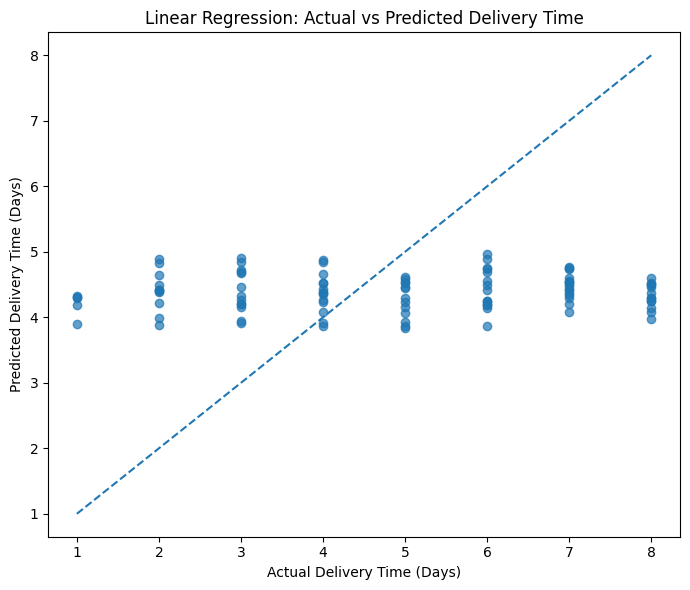

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, linear_pred, alpha=0.7)
low = min(y_test.min(), linear_pred.min())
high = max(y_test.max(), linear_pred.max())
ax.plot([low, high], [low, high], linestyle="--")
ax.set(title="Linear Regression: Actual vs Predicted Delivery Time",
       xlabel="Actual Delivery Time (Days)", ylabel="Predicted Delivery Time (Days)")
fig.tight_layout()
fig.savefig("../visualizations/Actual_vs_Predicted_Delivery_Time.png", dpi=220, bbox_inches="tight")
plt.show()


## 7. Interpretation and limitations

The delivery-time target was randomly generated. All test R² scores are negative, so these models did not outperform a simple mean-based baseline on this test set. The models are educational demonstrations, not operational forecasts. Real historical delivery timestamps, route conditions, traffic, vehicle capacity, and delay reasons would be needed for a useful production model.